# Code

## Simple LinReg Model

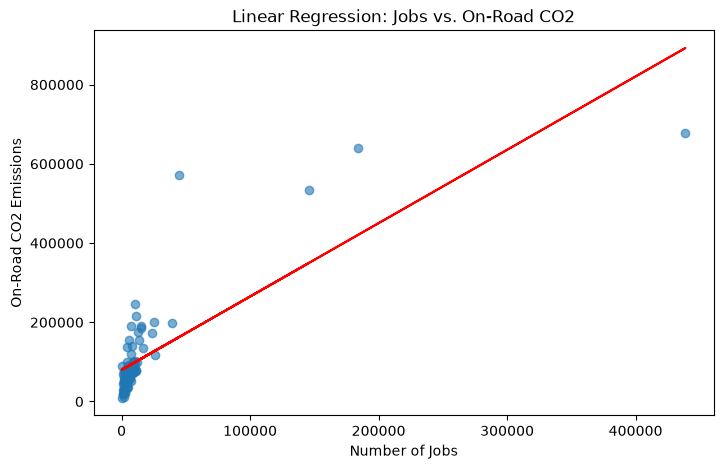

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

emis = pd.read_csv(r"Socioeconomic-Health-Disparities\data\CommunityAreas_LocalEmission2019.csv")

# X = Jobs, Y = On-road CO2
X = emis["JOBS"]
Y = emis["ONROAD_CO2"]

# Fit linear regression
X_const = sm.add_constant(X)
linear_model = sm.OLS(Y, X_const).fit()

plt.figure(figsize=(8, 5))
plt.scatter(X, Y, alpha=0.6)
plt.plot(X, linear_model.fittedvalues, color="red")

plt.xlabel("Number of Jobs")
plt.ylabel("On-Road CO2 Emissions")
plt.title("Linear Regression: Jobs vs. On-Road CO2")
plt.show()

In [14]:
print(linear_model.summary())


                            OLS Regression Results                            
Dep. Variable:             ONROAD_CO2   R-squared:                       0.640
Model:                            OLS   Adj. R-squared:                  0.635
Method:                 Least Squares   F-statistic:                     133.5
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           2.56e-18
Time:                        17:18:35   Log-Likelihood:                -975.16
No. Observations:                  77   AIC:                             1954.
Df Residuals:                      75   BIC:                             1959.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       7.985e+04   9250.584      8.632      0.0

## LINE test for Simple LinReg Model 

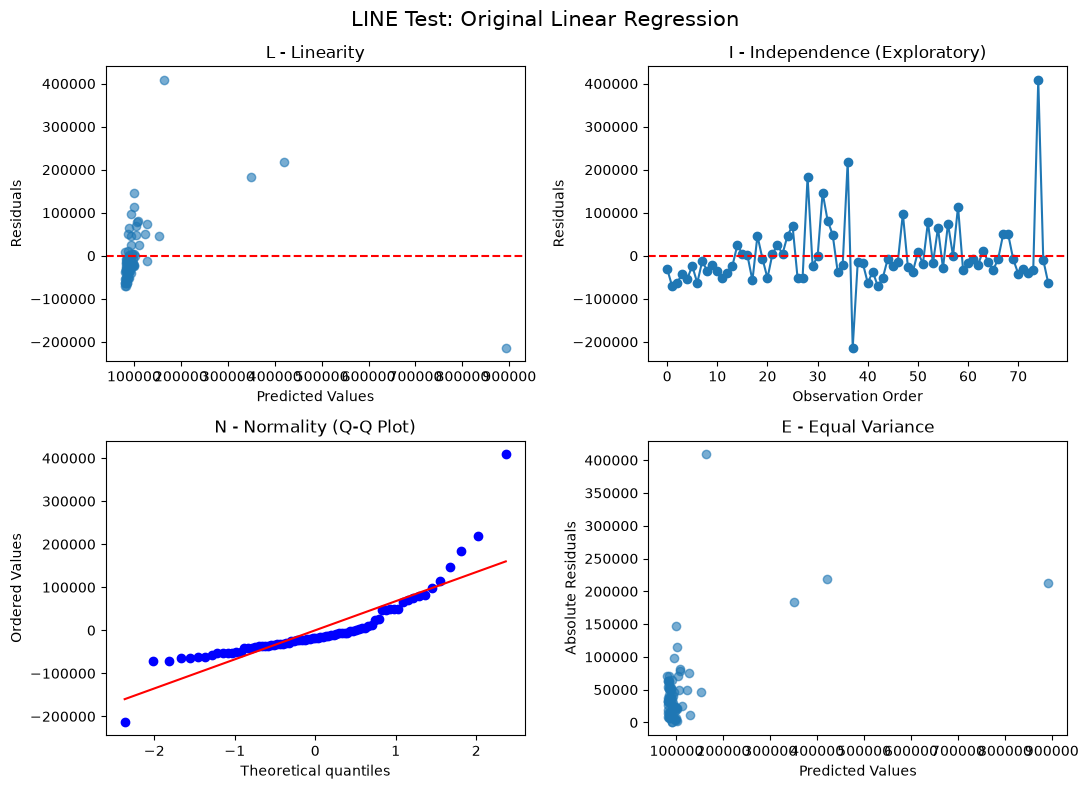

In [6]:

def line_test(model, title):
    residuals = model.resid
    fitted = model.fittedvalues

    fig, axes = plt.subplots(2, 2, figsize=(11, 8))

    # L - Linearity
    axes[0, 0].scatter(fitted, residuals, alpha=0.6)
    axes[0, 0].axhline(0, color="red", linestyle="--")
    axes[0, 0].set_title("L - Linearity")
    axes[0, 0].set_xlabel("Predicted Values")
    axes[0, 0].set_ylabel("Residuals")

    # I - Independence
    axes[0, 1].plot(range(len(residuals)), residuals, marker="o")
    axes[0, 1].axhline(0, color="red", linestyle="--")
    axes[0, 1].set_title("I - Independence (Exploratory)")
    axes[0, 1].set_xlabel("Observation Order")
    axes[0, 1].set_ylabel("Residuals")

    # N - Normality
    stats.probplot(residuals, dist="norm", plot=axes[1, 0])
    axes[1, 0].set_title("N - Normality (Q-Q Plot)")

    # E - Equal Variance
    axes[1, 1].scatter(fitted, np.abs(residuals), alpha=0.6)
    axes[1, 1].set_title("E - Equal Variance")
    axes[1, 1].set_xlabel("Predicted Values")
    axes[1, 1].set_ylabel("Absolute Residuals")

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

line_test(linear_model, "LINE Test: Original Linear Regression")


## Simple LogReg Model

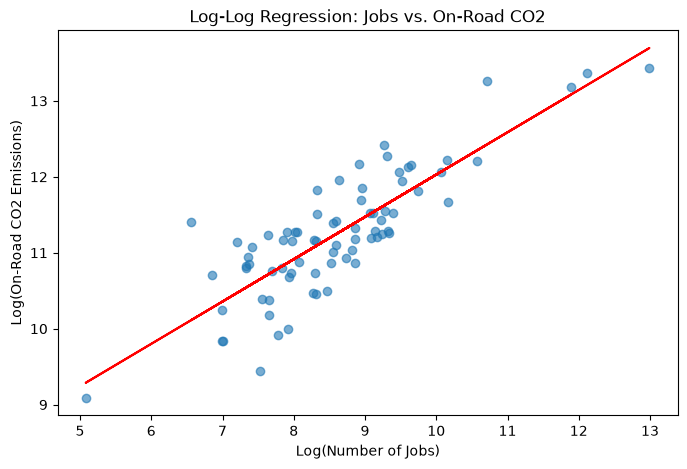

In [15]:

# Log-transform both variables
X_log = np.log(emis["JOBS"])
Y_log = np.log(emis["ONROAD_CO2"])

# Fit log-log regression
X_log_const = sm.add_constant(X_log)
log_model = sm.OLS(Y_log, X_log_const).fit()

plt.figure(figsize=(8, 5))
plt.scatter(X_log, Y_log, alpha=0.6)
plt.plot(X_log, log_model.fittedvalues, color="red")

plt.xlabel("Log(Number of Jobs)")
plt.ylabel("Log(On-Road CO2 Emissions)")
plt.title("Log-Log Regression: Jobs vs. On-Road CO2")
plt.show()


In [16]:
print(log_model.summary())

                            OLS Regression Results                            
Dep. Variable:             ONROAD_CO2   R-squared:                       0.704
Model:                            OLS   Adj. R-squared:                  0.700
Method:                 Least Squares   F-statistic:                     178.6
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.56e-21
Time:                        17:20:28   Log-Likelihood:                -46.920
No. Observations:                  77   AIC:                             97.84
Df Residuals:                      75   BIC:                             102.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.4569      0.362     17.828      0.0

## LINE test for Simple LogReg Model

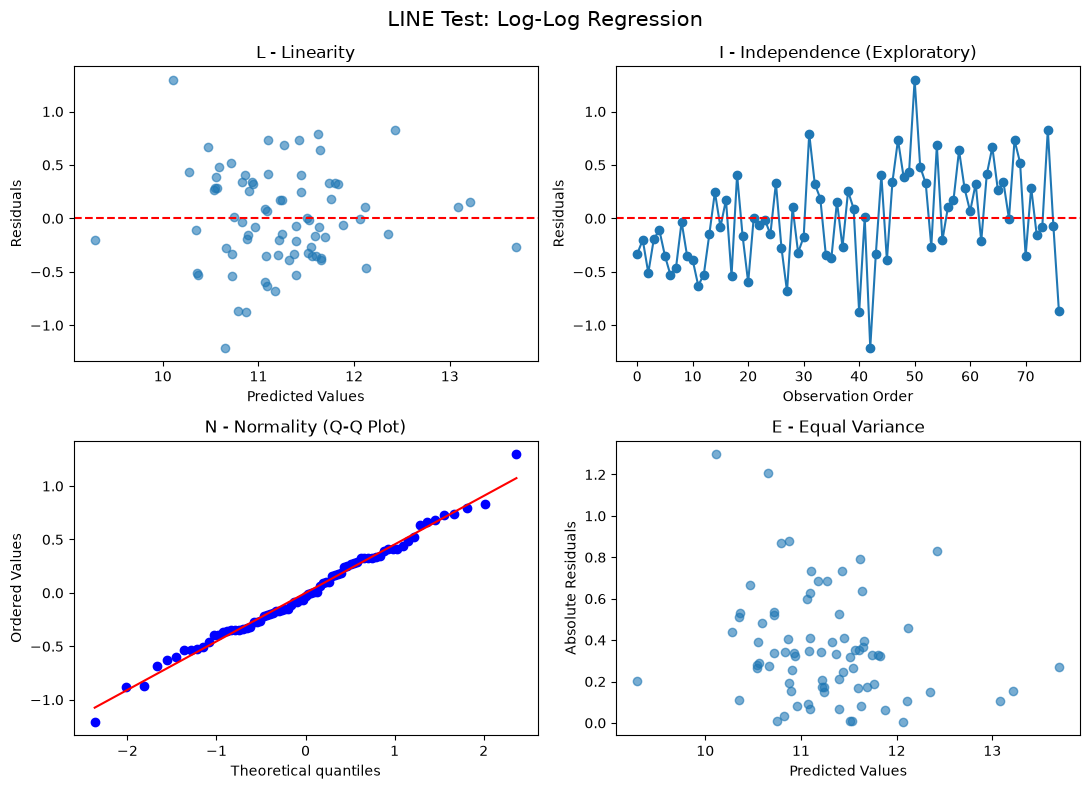

In [8]:

line_test(log_model, "LINE Test: Log-Log Regression")


In [11]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp = het_breuschpagan(
    log_model.resid,
    log_model.model.exog
)

print("Breusch-Pagan p-value:", bp[1])

Breusch-Pagan p-value: 0.04543672701757436


In [10]:

log_model_robust = sm.OLS(
    Y_log,
    X_log_const
).fit(cov_type="HC3")

print(log_model_robust.summary())


                            OLS Regression Results                            
Dep. Variable:             ONROAD_CO2   R-squared:                       0.704
Model:                            OLS   Adj. R-squared:                  0.700
Method:                 Least Squares   F-statistic:                     175.2
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           2.62e-21
Time:                        14:42:31   Log-Likelihood:                -46.920
No. Observations:                  77   AIC:                             97.84
Df Residuals:                      75   BIC:                             102.5
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.4569      0.383     16.875      0.0

## Independent Variable Explanatory Power - LogReg Model

In [ ]:

# Hypothesis Test: Does JOBS significantly explain variability in ONROAD_CO2?

alpha = 0.05

# H0: beta_1 = 0
# Ha: beta_1 != 0

beta1 = log_model_robust.params["JOBS"]
p_value = log_model_robust.pvalues["JOBS"]
ci = log_model_robust.conf_int().loc["JOBS"]

print("H0: beta_1 = 0")
print("Ha: beta_1 != 0")
print("Significance level:", alpha)

print("\nEstimated beta_1:", round(beta1, 4))
print("P-value:", p_value)
print("95% Confidence Interval:", ci.tolist())

if p_value < alpha:
    print("\nReject H0.")
    print("Jobs are a statistically significant predictor of on-road CO2 emissions.")
else:
    print("\nFail to reject H0.")
    print("Insufficient evidence that jobs are a statistically significant predictor.")


H0: beta_1 = 0
Ha: beta_1 != 0
Significance level: 0.05

Estimated beta_1: 0.5572
P-value: 5.46427699048588e-40
95% Confidence Interval: [0.47471857157403785, 0.6397521925485994]

Reject H0.
Jobs are a statistically significant predictor of on-road CO2 emissions.


# Analysis

Based on the below correlation coefficienct matrix, taken from the eda notebook, we can see that there's a pearson r coefficient of 0.800 between number of jobs and Onroad CO2 emissions. I decided to explore this connection further by trying to create a [Linear Regression Model](#simple-linreg-model) to see if we can justify Income having any explanatory power on Onroad CO2. 

shape: (5, 6)
┌────────────┬──────────┬──────────┬──────────┬────────────┬────────────┐
│ Variable   ┆ POP      ┆ JOBS     ┆ INCOME   ┆ ONROAD_CO2 ┆ NONRES_ELE │
│ ---        ┆ ---      ┆ ---      ┆ ---      ┆ ---        ┆ ---        │
│ str        ┆ f64      ┆ f64      ┆ f64      ┆ f64        ┆ f64        │
╞════════════╪══════════╪══════════╪══════════╪════════════╪════════════╡
│ POP        ┆ 1.0      ┆ 0.259841 ┆ 0.310621 ┆ 0.456785   ┆ 0.404039   │
│ JOBS       ┆ 0.259841 ┆ 1.0      ┆ 0.370146 ┆ 0.800138   ┆ 0.91646    │
│ INCOME     ┆ 0.310621 ┆ 0.370146 ┆ 1.0      ┆ 0.357041   ┆ 0.385903   │
│ ONROAD_CO2 ┆ 0.456785 ┆ 0.800138 ┆ 0.357041 ┆ 1.0        ┆ 0.83165    │
│ NONRES_ELE ┆ 0.404039 ┆ 0.91646  ┆ 0.385903 ┆ 0.83165    ┆ 1.0        │
└────────────┴──────────┴──────────┴──────────┴────────────┴────────────┘

However upon performing the [LINE test for the linear regression model](#line-test-for-simple-linreg-model), it was quite clear to see that multiple assumptions were not met. the Q-Q plot is not linear, Equal variance of errors is not met (distribution heavily skewed right). Using Boxcox (procedure not shown), I determined that a [log regression model](#simple-logreg-model) was most appropriate. After performing this transformation I now did a [LINE test for the log regression model](#line-test-for-simple-logreg-model), and the results were much better. Normality was now met, and Linearity and Equal Variance were reasonably met. The real problem is independence, as there does seem to be a very slight upwards pattern in the residuals, *however* this could also be because of the order of the communities in the dataset. To further verify I found the Breusch-Pagan p-value which was 0.045, just slightly under 0.05, so we cannot entirely rule out the possibility of dependence. To address this limitation, we used HC3 heteroskedasticity-robust standard errors, where we got p < 0.001, with a 95% CI of (0.475, 0.640), B_1 = 0.5572. As our 95% CI does not include 0 and we have a P-value of less than 0.05, we determine that the relationship between jobs and on-road CO2 emissions remains statistically significant. However this does not mean jobs impacts these emissions.

To verify whether or not Jobs significantly impact variability in Onroad CO2 emissions, we perform a [two sided Wald Z test](#independent-variable-explanatory-power---logreg-model). From the results we can see that we reject our Null hypothesis, meaning there is sufficient evidence that the number of jobs are a statistically significant predictor of on-road CO2 emissions.